# Figure 4a. Initiating-recipient cell-type configurations

Proportion of the 4,023 *cis*-*trans* colocalized loci (CoS supported by a *cis*-eQTL and by at least one *trans*-eGene or *trans*-eProgram) in each of six mutually exclusive configurations. The initiating set is the snRNA-seq cell types with *cis* support (DeJager), the recipient set is the cell types with *trans* support (eGene union eProgram); bulk (ROSMAP DLPFC/AC/PCC) support is used only when a side has no cell type. Identical: equal sets; Overlapping: shared but unequal sets; Distinct: disjoint sets. Counts are shown at the bar ends; no statistical test.

Input: `data/Figure_4a_configuration_counts.rds`

In [1]:
library(ggplot2)
library(scales)
res <- readRDS("data/Figure_4a_configuration_counts.rds")
res

category,n_loci,total,proportion
<fct>,<int>,<int>,<dbl>
Identical initiating-recipient,73,4023,0.01814566
Overlapping initiating-recipient,1245,4023,0.30947054
Distinct initiating-recipient,1301,4023,0.32339050
Bulk-only initiating support,1037,4023,0.25776783
Bulk-only recipient support,264,4023,0.06562267
Bulk-only initiating-recipient support,103,4023,0.02560278


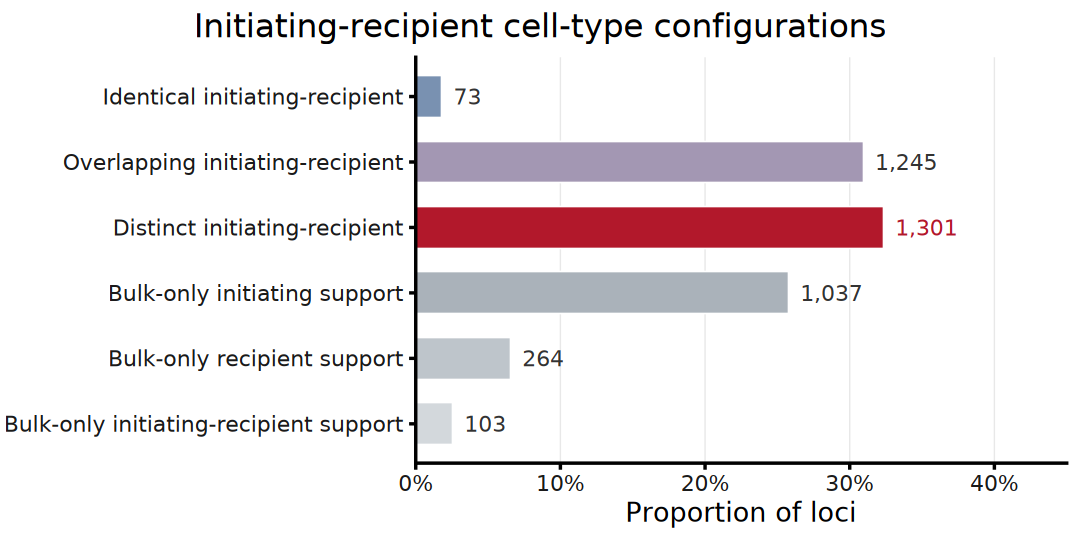

In [2]:
bar_cols <- c("#7991B1", "#A397B3", "#B2182B", "#AAB2BA", "#BEC5CB", "#D3D8DC")
names(bar_cols) <- levels(res$category)
res$label_col <- ifelse(res$category == "Distinct initiating-recipient", "#B2182B", "grey20")

p <- ggplot(res, aes(x = proportion, y = category, fill = category)) +
  geom_col(width = 0.64, colour = "white", linewidth = 0.35) +
  geom_text(aes(x = proportion + 0.008, label = comma(n_loci), colour = label_col),
            hjust = 0, size = 4.5) +
  scale_fill_manual(values = bar_cols, guide = "none") +
  scale_colour_identity() +
  scale_y_discrete(limits = rev(levels(res$category))) +
  scale_x_continuous(limits = c(0, 0.45), breaks = seq(0, 0.4, 0.1),
                     labels = label_percent(accuracy = 1), expand = c(0, 0)) +
  labs(title = "Initiating-recipient cell-type configurations",
       x = "Proportion of loci", y = NULL) +
  theme_classic(base_size = 16) +
  theme(plot.title = element_text(hjust = 0.5, face = "italic"),
        plot.title.position = "plot",
        panel.grid.major.x = element_line(colour = "grey91", linewidth = 0.3),
        axis.text = element_text(colour = "grey10"))

options(repr.plot.width = 9, repr.plot.height = 4.5)
p